/usr/local/lib/python3.11/dist-packages/torch/nn/modules/transformer.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  warnings.warn(


Epoch 1: Loss = 0.2627
Epoch 2: Loss = 0.0034
Epoch 3: Loss = 0.0012
Epoch 4: Loss = 0.0006
Epoch 5: Loss = 0.0004


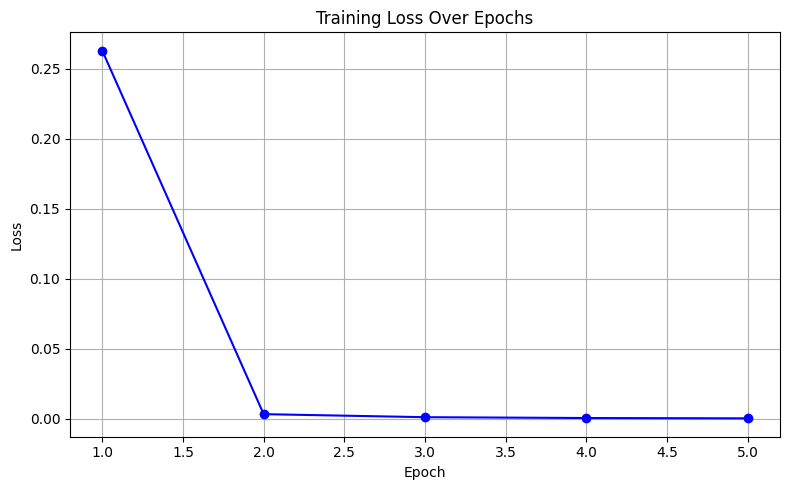

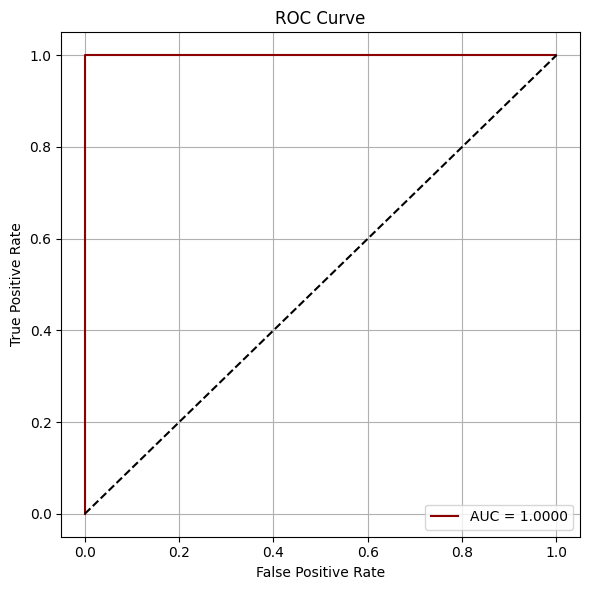

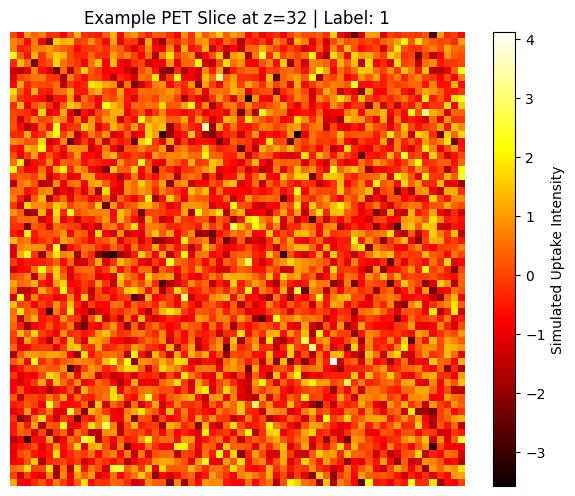

In [ ]:
!pip install torch torchvision monai nibabel scikit-learn matplotlib einops --quiet

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from einops import rearrange
from sklearn.metrics import roc_curve, roc_auc_score
import numpy as np

# --- Define Model ---
class ViT3D(nn.Module):
    def __init__(self, img_size=64, patch_size=16, emb_dim=256, depth=6, num_heads=8, mlp_dim=512, num_classes=1):
        super().__init__()
        self.num_patches = (img_size // patch_size) ** 3
        self.patch_dim = patch_size ** 3 * 1
        self.patch_embedding = nn.Linear(self.patch_dim, emb_dim)
        self.cls_token = nn.Parameter(torch.randn(1, 1, emb_dim))
        self.pos_embedding = nn.Parameter(torch.randn(1, self.num_patches + 1, emb_dim))

        encoder_layer = nn.TransformerEncoderLayer(d_model=emb_dim, nhead=num_heads, dim_feedforward=mlp_dim)
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=depth)

        self.mlp_head = nn.Sequential(
            nn.LayerNorm(emb_dim),
            nn.Linear(emb_dim, num_classes)
        )

    def forward(self, x):
        B, C, D, H, W = x.shape
        patches = rearrange(x, 'b c (d p1) (h p2) (w p3) -> b (d h w) (c p1 p2 p3)', p1=16, p2=16, p3=16)
        x = self.patch_embedding(patches)
        cls_tokens = self.cls_token.expand(B, -1, -1)
        x = torch.cat((cls_tokens, x), dim=1)
        x = x + self.pos_embedding
        x = x.permute(1, 0, 2)
        x = self.transformer(x)
        x = x.permute(1, 0, 2)
        x_cls = x[:, 0]
        return self.mlp_head(x_cls).squeeze(-1)

# --- Create Dummy Dataset ---
class DummyPETDataset(Dataset):
    def __init__(self, n_samples=200, img_shape=(64, 64, 64)):
        self.data = torch.randn(n_samples, 1, *img_shape)
        self.labels = torch.randint(0, 2, (n_samples,), dtype=torch.float32)
        for i in range(n_samples):
            if self.labels[i] == 1:
                self.data[i, 0, 20:30, 20:30, 20:30] += 3.0

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        return self.data[idx], self.labels[idx]

# --- Instantiate Everything ---
dataset = DummyPETDataset()
train_loader = DataLoader(dataset, batch_size=8, shuffle=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = ViT3D().to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-4)
criterion = nn.BCEWithLogitsLoss()

# --- Training Loop with Loss Tracking ---
train_losses = []

def train(model, loader, optimizer, criterion, epochs=5):
    model.train()
    for epoch in range(epochs):
        total_loss = 0
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        avg_loss = total_loss / len(loader)
        train_losses.append(avg_loss)
        print(f"Epoch {epoch+1}: Loss = {avg_loss:.4f}")

train(model, train_loader, optimizer, criterion)

# --- Loss Curve Plot ---
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(train_losses)+1), train_losses, marker='o', color='blue')
plt.title('Training Loss Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True)
plt.tight_layout()
plt.show()

# --- ROC Curve ---
model.eval()
all_labels, all_preds = [], []
with torch.no_grad():
    for imgs, labels in train_loader:
        imgs = imgs.to(device)
        outputs = model(imgs)
        all_labels.extend(labels.numpy())
        all_preds.extend(torch.sigmoid(outputs).cpu().numpy())

fpr, tpr, _ = roc_curve(all_labels, all_preds)
auc = roc_auc_score(all_labels, all_preds)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f'AUC = {auc:.4f}', color='darkred')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()
plt.show()

# --- Visualize a PET Image Slice (heatmap) ---
example_img, label = dataset[0]
slice_index = 32  # mid-brain slice

plt.figure(figsize=(6, 5))
plt.imshow(example_img[0, :, :, slice_index], cmap='hot')
plt.title(f'Example PET Slice at z={slice_index} | Label: {int(label.item())}')
plt.colorbar(label='Simulated Uptake Intensity')
plt.axis('off')
plt.tight_layout()
plt.show()
